# Predicting Tomorrow's Subway Ridership at Every NYC Station
**NYC in Motion Datathon — Rutgers DSC, Fall 2026**

**Problem.** The MTA has to decide each day how many trains, station staff and cleaning crews to send to 424 subway station complexes. If it plans with simple rules of thumb like "same as last week" or "the usual average", it puts people in the wrong places whenever ridership shifts. That happens with holidays, schools reopening, or rain.

**Question.** Using only data available the day before, how accurately can we predict each station's entries for the next day? Does a model beat the simple rules of thumb?

**Data.** MTA daily station-complex entries plus NOAA daily weather (Central Park), Aug 1 – Sep 30, 2025.

**Method.** Train on **August** and test on **September**, a period the model never sees during training. We compare against two baselines.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

DATA = 'data/public'
BLUE, ORANGE, GRAY, INK, INK2 = '#2a78d6', '#eb6834', '#8a8984', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#d6d5d0',
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#ecebe7',
                     'grid.linewidth': 0.8, 'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': INK2,
                     'ytick.color': INK2, 'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
                     'axes.titlelocation': 'left', 'axes.axisbelow': True})
import matplotlib.dates as mdates
def fmt_dates(ax):
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
import os; os.makedirs('figures', exist_ok=True)

## 1. Load and combine the data

In [2]:
mta = pd.read_csv(f'{DATA}/mta_station_daily_aug_sep_2025.csv', parse_dates=['service_date'])
mta = mta.rename(columns={'service_date': 'date', 'station_complex_id': 'sid'})
names = mta.groupby('sid')[['station_complex', 'borough']].first()

w = pd.read_csv(f'{DATA}/noaa_daily_weather_aug_sep_2025.csv', parse_dates=['DATE'])
w = (w[w.NAME.str.contains('CENTRAL PARK')]
       .rename(columns={'DATE': 'date', 'PRCP': 'rain_mm', 'TMAX': 'tmax_c'})[['date', 'rain_mm', 'tmax_c']])

# One row per station per calendar day (a few station-days are missing in the source)
grid = pd.MultiIndex.from_product([mta.sid.unique(), pd.date_range('2025-08-01', '2025-09-30')],
                                  names=['sid', 'date']).to_frame(index=False)
df = grid.merge(mta[['sid', 'date', 'entries']], how='left').merge(w, on='date').sort_values(['sid', 'date'])
print(f"{mta.sid.nunique()} station complexes, {mta.date.nunique()} days, {len(mta):,} station-days, "
      f"{df.entries.isna().sum()} missing station-days")

424 station complexes, 61 days, 25,820 station-days, 44 missing station-days


## 2. What does ridership look like?

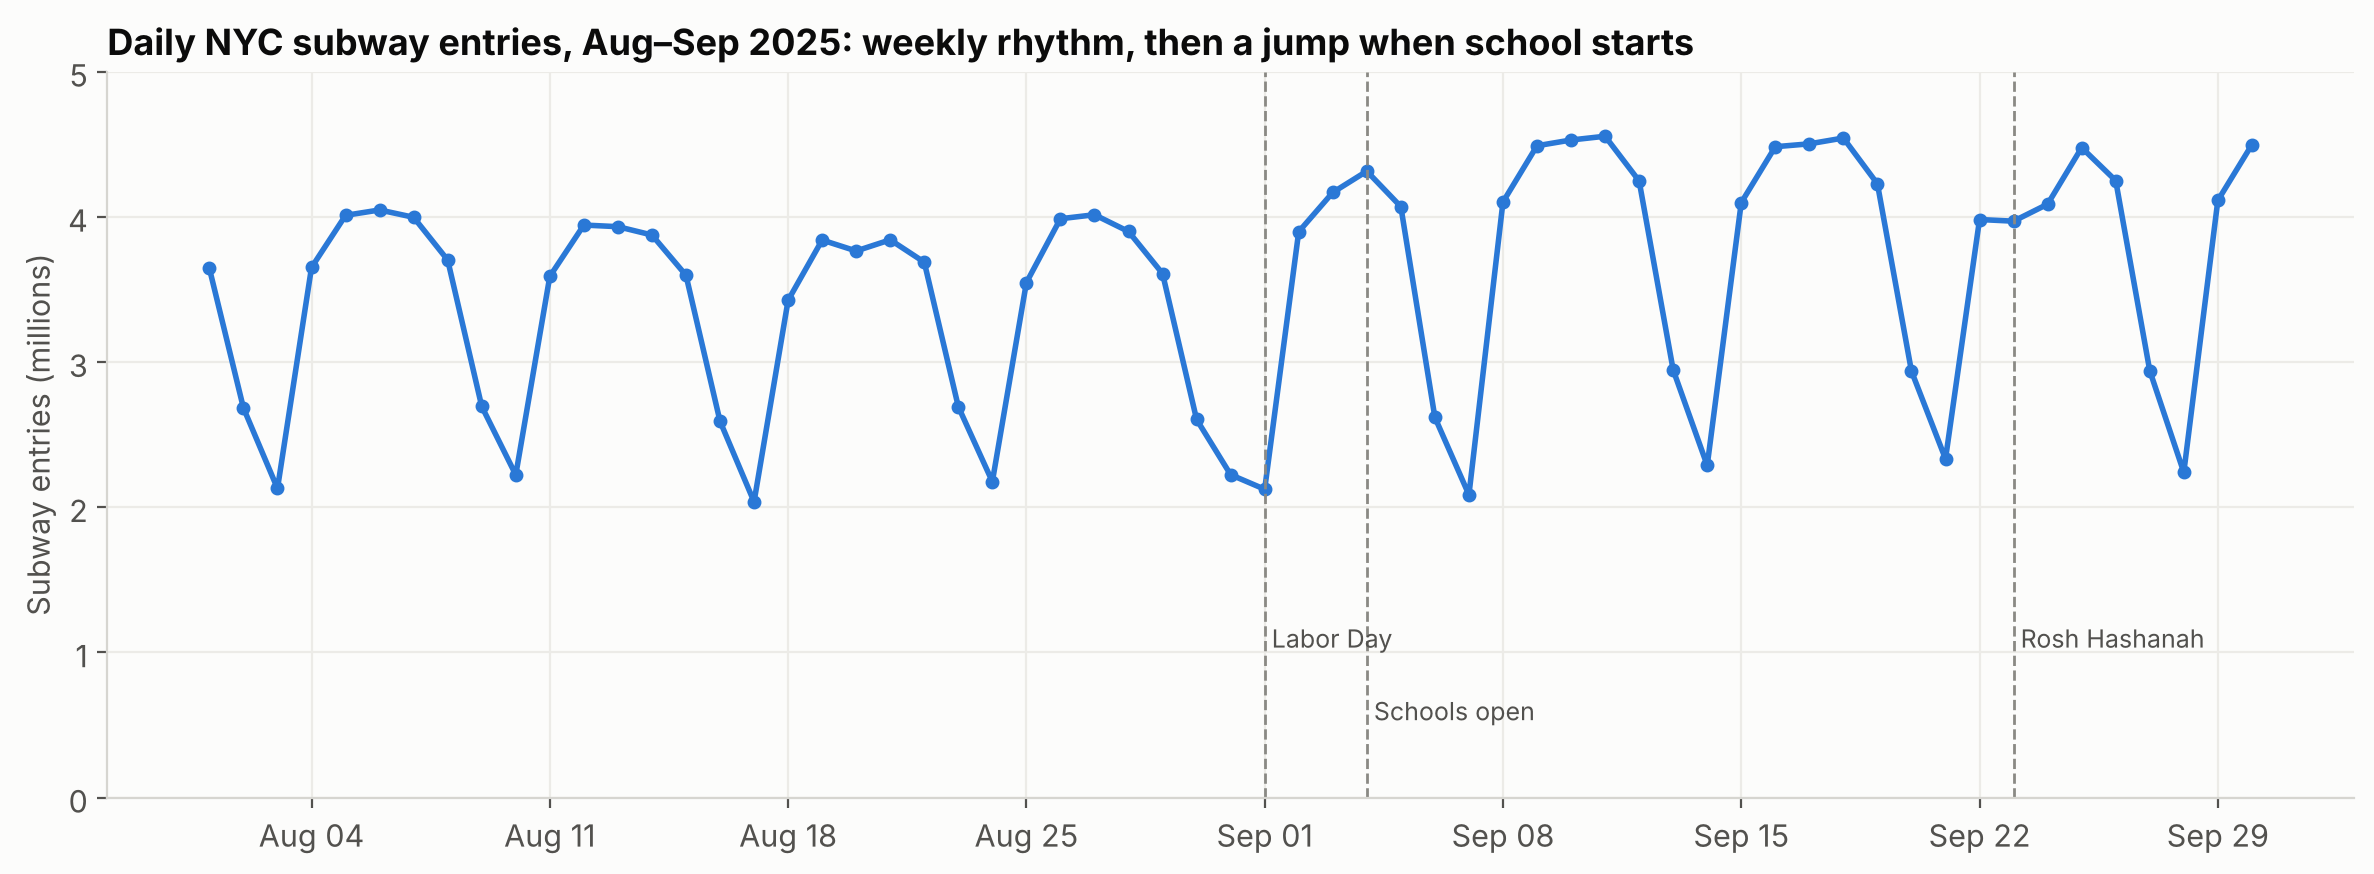

Average weekday: August 3.79M  ->  September (after Labor Day week) 4.34M  (+14%)


In [3]:
SCHOOL_START, LABOR_DAY = pd.Timestamp('2025-09-04'), pd.Timestamp('2025-09-01')
ROSH = [pd.Timestamp('2025-09-23'), pd.Timestamp('2025-09-24')]
daily = df.groupby('date').agg(entries=('entries', 'sum'), rain_mm=('rain_mm', 'first'))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily.entries / 1e6, color=BLUE, lw=2, marker='o', ms=4)
ax.set_ylabel('Subway entries (millions)'); ax.set_ylim(0, 5)
for d, label, y in [(LABOR_DAY, 'Labor Day', 1.2), (SCHOOL_START, 'Schools open', 0.7), (ROSH[0], 'Rosh Hashanah', 1.2)]:
    ax.axvline(d, color=GRAY, ls='--', lw=1); ax.text(d, y, ' ' + label, color=INK2, fontsize=9, va='top')
fmt_dates(ax)
aug_wd = daily[(daily.index < '2025-09-01') & (daily.index.dayofweek < 5)].entries.mean()
sep_wd = daily[(daily.index >= '2025-09-08') & (daily.index.dayofweek < 5) & ~daily.index.isin(ROSH)].entries.mean()
ax.set_title('Daily NYC subway entries, Aug–Sep 2025: weekly rhythm, then a jump when school starts')
plt.tight_layout(); plt.savefig('figures/01_daily_ridership.png', dpi=150); plt.show()
print(f"Average weekday: August {aug_wd/1e6:.2f}M  ->  September (after Labor Day week) {sep_wd/1e6:.2f}M  "
      f"(+{sep_wd/aug_wd-1:.0%})")

**What this shows:**
- There's a strong **weekly rhythm**. Weekdays run about 3.5–4.5M entries and Sundays about 2M.
- **September is clearly busier than August** because schools reopen and people come back from summer. A forecast built on "the August average" will be wrong all month.
- **Holidays** (Labor Day) and **school closures** (Rosh Hashanah, Sept 23–24) cause sharp one-day drops.

## 3. Does rain matter?

In [4]:
# Compare each weekday to the average of the same weekday in the same month to remove the weekly and school effects
d2 = daily.copy(); d2['dow'] = d2.index.dayofweek; d2['month'] = d2.index.month
d2 = d2[(d2.dow < 5) & (d2.index != LABOR_DAY) & ~d2.index.isin(ROSH)]
d2['vs_typical'] = d2.entries / d2.groupby(['month', 'dow']).entries.transform('mean') - 1
d2['rainy'] = d2.rain_mm >= 5
r = d2.groupby('rainy').vs_typical.agg(['mean', 'count'])
print(r.rename(index={False: 'dry / light rain (<5mm)', True: 'rainy (>=5mm)'}).round(3))

                          mean  count
rainy                                
dry / light rain (<5mm)  0.003     35
rainy (>=5mm)           -0.019      5


On rainy weekdays (5 mm or more), ridership ran about **2% below** a typical day of the same weekday. But that's based on only **5 rainy weekdays**, so treat it as a hint, not a proven effect. We still give rainfall and temperature to the model as inputs.

## 4. Build the forecast

**Everything the model uses is known the day before:**
| Input | Meaning |
|---|---|
| `day_type` | Day of week. A holiday counts as a Sunday |
| `holiday` | Labor Day flag |
| `rain_mm`, `tmax_c` | That day's weather. In real use this would come from the weather forecast |
| `lag1_r` | Yesterday's entries ÷ the station's 7-day average |
| `lag7_r` | Same day last week ÷ the station's 7-day average |

The model predicts **tomorrow ÷ the station's recent 7-day average**, so one model works for small and huge stations alike. We then multiply back to get entries.

In [5]:
df['holiday'] = (df.date == LABOR_DAY).astype(int)
df['dow'] = df.date.dt.dayofweek
df['day_type'] = np.where(df.holiday == 1, 6, df.dow)

# So the holiday doesn't distort next week's "last week" inputs, swap its value for the week before when computing history
hist = df.entries.copy()
hist[df.holiday == 1] = df.groupby('sid').entries.shift(7)[df.holiday == 1]
df['hist'] = hist
g = df.groupby('sid')['hist']
df['lag1'] = g.shift(1)
df['lag7'] = g.shift(7)
df['roll7'] = g.transform(lambda s: s.shift(1).rolling(7, min_periods=5).mean())
df['lag1_r'] = df.lag1 / df.roll7
df['lag7_r'] = df.lag7 / df.roll7
df['target_r'] = df.entries / df.roll7

FEATS = ['day_type', 'holiday', 'rain_mm', 'tmax_c', 'lag1_r', 'lag7_r']
train = df[(df.date >= '2025-08-08') & (df.date <= '2025-08-31')].dropna(subset=['entries', 'roll7', 'lag7'])
test = df[df.date >= '2025-09-01'].dropna(subset=['entries', 'roll7']).copy()
print(f'Train: {train.date.min():%b %d}–{train.date.max():%b %d} ({len(train):,} rows)   '
      f'Test: {test.date.min():%b %d}–{test.date.max():%b %d} ({len(test):,} rows)')

model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, categorical_features=[0], random_state=0)
model.fit(train[FEATS], train.target_r, sample_weight=train.roll7)   # weight by size: big stations matter more
test['Model'] = model.predict(test[FEATS]) * test.roll7

Train: Aug 08–Aug 31 (10,137 rows)   Test: Sep 01–Sep 30 (12,698 rows)


## 5. Baselines: the simple rules of thumb we have to beat
- **Baseline A — "August average":** the station's average for that weekday in August.
- **Baseline B — "Same day last week":** last week's number for that station.

In [6]:
aug = df[df.date <= '2025-08-31']
test = test.join(aug.groupby(['sid', 'day_type']).entries.mean().rename('Baseline A: August average'),
                 on=['sid', 'day_type'])
test['Baseline B: same day last week'] = test.lag7

METHODS = ['Baseline A: August average', 'Baseline B: same day last week', 'Model']
def wape(y, p):
    ok = p.notna(); return (y[ok] - p[ok]).abs().sum() / y[ok].sum()

res = pd.DataFrame({
    'Error, % of riders (WAPE)': [wape(test.entries, test[m]) for m in METHODS],
    'Avg miss per station-day (MAE)': [(test.entries - test[m]).abs().mean() for m in METHODS],
}, index=METHODS)
res['Error, % of riders (WAPE)'] = (res['Error, % of riders (WAPE)'] * 100).round(1)
res['Avg miss per station-day (MAE)'] = res['Avg miss per station-day (MAE)'].round(0).astype(int)
res

,"Error, % of riders (WAPE)",Avg miss per station-day (MAE)
Baseline A: August average,13.3,1173
Baseline B: same day last week,9.3,824
Model,7.4,650


**WAPE** (weighted absolute percentage error) = total riders we mis-predicted ÷ total riders. Lower is better. *Example: 7% means that out of every 100 riders, we were off by about 7.*

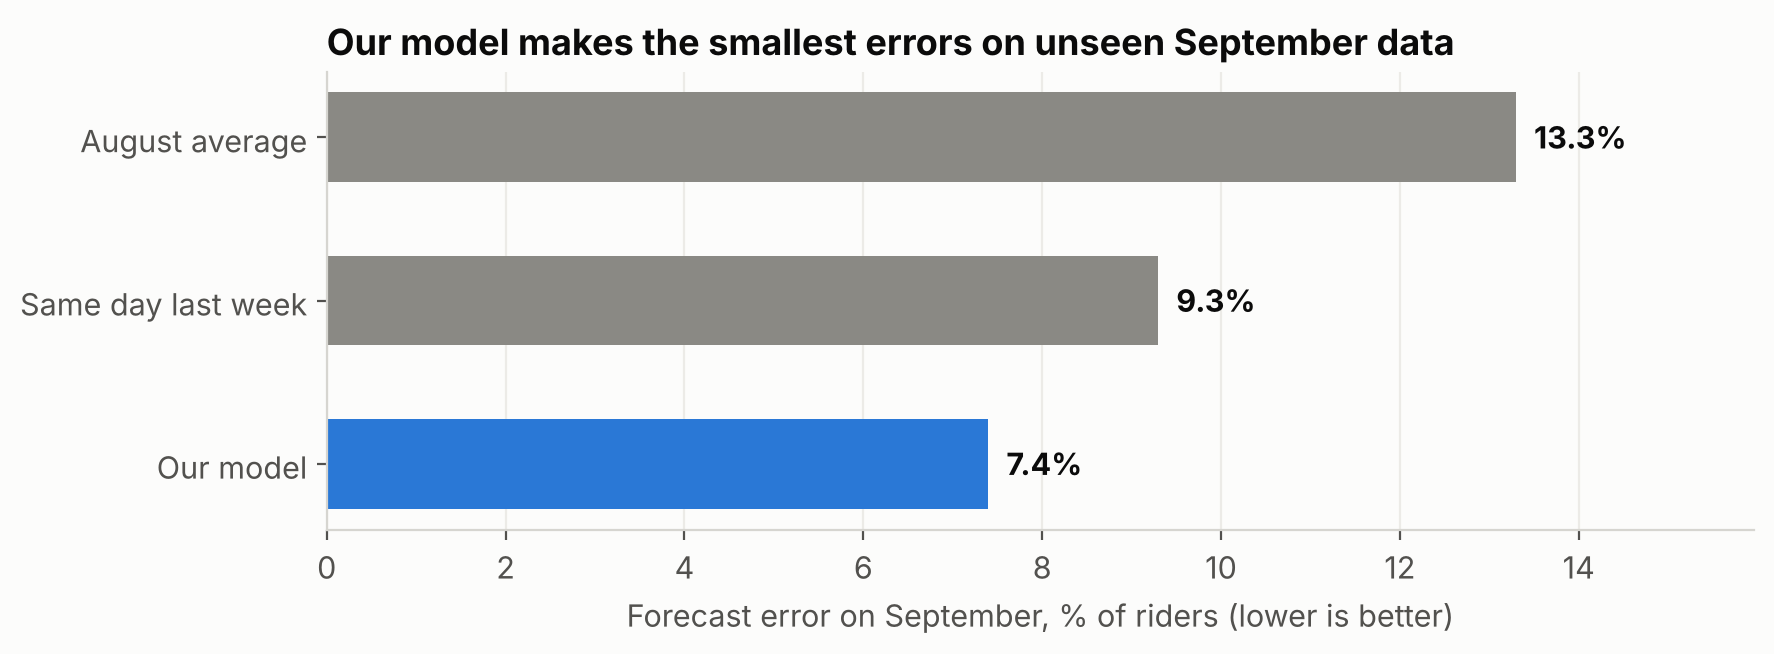

Model cuts error by 20% vs 'same day last week' and 44% vs 'August average'.


In [7]:
fig, ax = plt.subplots(figsize=(9, 3.4))
vals = res['Error, % of riders (WAPE)']
bars = ax.barh(['August average', 'Same day last week', 'Our model'][::-1], vals.values[::-1],
               color=[BLUE, GRAY, GRAY], height=0.55)
for b, v in zip(bars, vals.values[::-1]):
    ax.text(v + 0.2, b.get_y() + b.get_height() / 2, f'{v:.1f}%', va='center', color=INK, fontweight='bold')
ax.set_xlabel('Forecast error on September, % of riders (lower is better)'); ax.grid(axis='y', visible=False)
ax.set_xlim(0, vals.max() * 1.2)
ax.set_title('Our model makes the smallest errors on unseen September data')
plt.tight_layout(); plt.savefig('figures/02_error_comparison.png', dpi=150); plt.show()
b = res['Error, % of riders (WAPE)']
print(f"Model cuts error by {1 - b['Model']/b['Baseline B: same day last week']:.0%} vs 'same day last week' "
      f"and {1 - b['Model']/b['Baseline A: August average']:.0%} vs 'August average'.")

## 6. Day by day: where does each method go wrong?

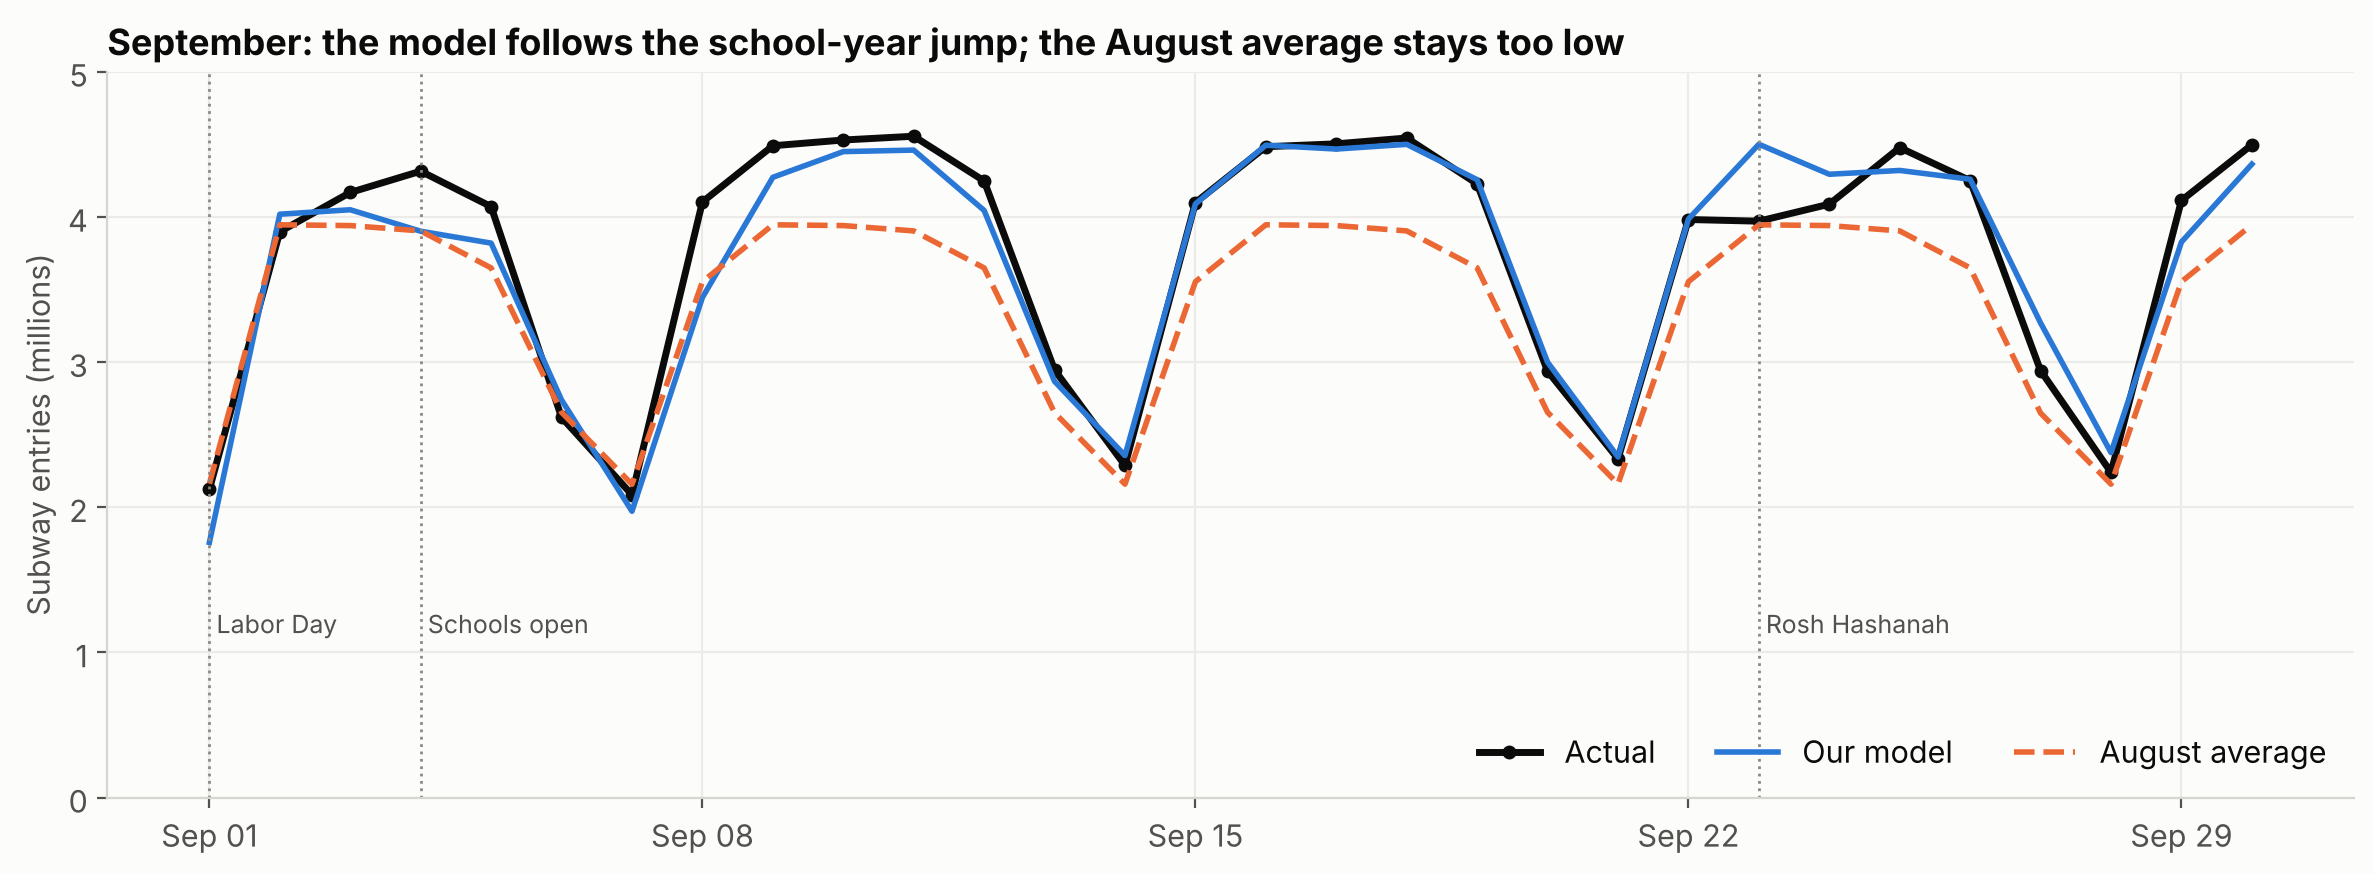

Largest misses for the model (system total, % over(+)/under(-) actual):
            Aug avg %  Last week %  Model %
date                                       
2025-09-01        1.8         67.0    -17.3
2025-09-08      -13.4        -13.5    -16.0
2025-09-23       -0.6         12.9     13.3
2025-09-27       -9.9         -0.1     11.2
2025-09-04       -9.5         -9.6     -9.6
2025-09-29      -13.6         -3.2     -7.0


In [8]:
s = test.groupby('date')[['entries'] + METHODS].sum(min_count=1)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(s.index, s.entries / 1e6, color=INK, lw=2.5, label='Actual', marker='o', ms=4)
ax.plot(s.index, s['Model'] / 1e6, color=BLUE, lw=2, label='Our model')
ax.plot(s.index, s['Baseline A: August average'] / 1e6, color=ORANGE, lw=2, ls='--', label='August average')
ax.set_ylabel('Subway entries (millions)'); ax.set_ylim(0, 5)
ax.legend(loc='lower right', frameon=False, ncol=3)
for d, label in [(LABOR_DAY, 'Labor Day'), (SCHOOL_START, 'Schools open'), (ROSH[0], 'Rosh Hashanah')]:
    ax.axvline(d, color=GRAY, ls=':', lw=1); ax.text(d, 1.3, ' ' + label, color=INK2, fontsize=9, va='top')
fmt_dates(ax)
ax.set_title('September: the model follows the school-year jump; the August average stays too low')
plt.tight_layout(); plt.savefig('figures/03_september_forecast.png', dpi=150); plt.show()

err = (s[METHODS].div(s.entries, axis=0) - 1).mul(100).round(1)
err.columns = ['Aug avg %', 'Last week %', 'Model %']
print('Largest misses for the model (system total, % over(+)/under(-) actual):')
print(err.reindex(err['Model %'].abs().sort_values(ascending=False).index).head(6))

**Reading the misses:**
- **Sept 4–8, schools reopen.** The model has only seen summer, so it under-predicts the first school days. It catches up within about a week because it relies on recent history.
- **Sept 1, Labor Day.** There are no holidays in the August training data, so the model can only treat the holiday "like a Sunday". That's close, but not exact.
- **Sept 23, Rosh Hashanah.** NYC public schools were closed, ridership dipped and every method over-predicted. **Lesson:** a school-calendar input would fix this. With only two months of data we can't learn that effect yet.

## 7. Where is the model least accurate?

In [9]:
test = test.join(names, on='sid')
by_b = (test.groupby('borough').apply(lambda d: pd.Series({
            'Model WAPE %': 100 * wape(d.entries, d['Model']),
            'Last-week WAPE %': 100 * wape(d.entries, d['Baseline B: same day last week']),
            'Avg daily entries': d.entries.mean()}), include_groups=False)
        .round(1).sort_values('Avg daily entries', ascending=False))
by_b

,Model WAPE %,Last-week WAPE %,Avg daily entries
borough,,,
Manhattan,6.6,8.5,17081.5
Queens,7.6,9.7,7161.4
Brooklyn,8.5,10.1,5405.6
Bronx,9.7,12.7,3901.6


In [10]:
big = test.groupby(['sid', 'station_complex']).apply(lambda d: pd.Series({
          'avg_entries': d.entries.mean(), 'model_wape_%': 100 * wape(d.entries, d['Model'])}), include_groups=False)
print('20 busiest stations — model error:')
big.sort_values('avg_entries', ascending=False).head(20).round(1)

20 busiest stations — model error:


,,avg_entries,model_wape_%
sid,station_complex,,
611,"Times Sq-42 St/Port Authority Bus Terminal (1,2,3,7,A,C,E,N,Q,R,W,S)",133645.4,3.9
610,"Grand Central-42 St (4,5,6,7,S)",103884.6,5.2
607,"34 St-Herald Sq (B,D,F,M,N,Q,R,W)",72167.6,4.3
602,"14 St-Union Sq (4,5,6,L,N,Q,R,W)",70347.6,5.7
628,"Fulton St (2,3,4,5,A,C,J,Z)",60840.7,5.0
164,"34 St-Penn Station (A,C,E)",58113.8,4.8
318,"34 St-Penn Station (1,2,3)",50867.2,5.5
614,"59 St-Columbus Circle (1,A,C,B,D)",50809.7,5.7
447,Flushing-Main St (7),44667.3,4.1


## 8. What does the model rely on?

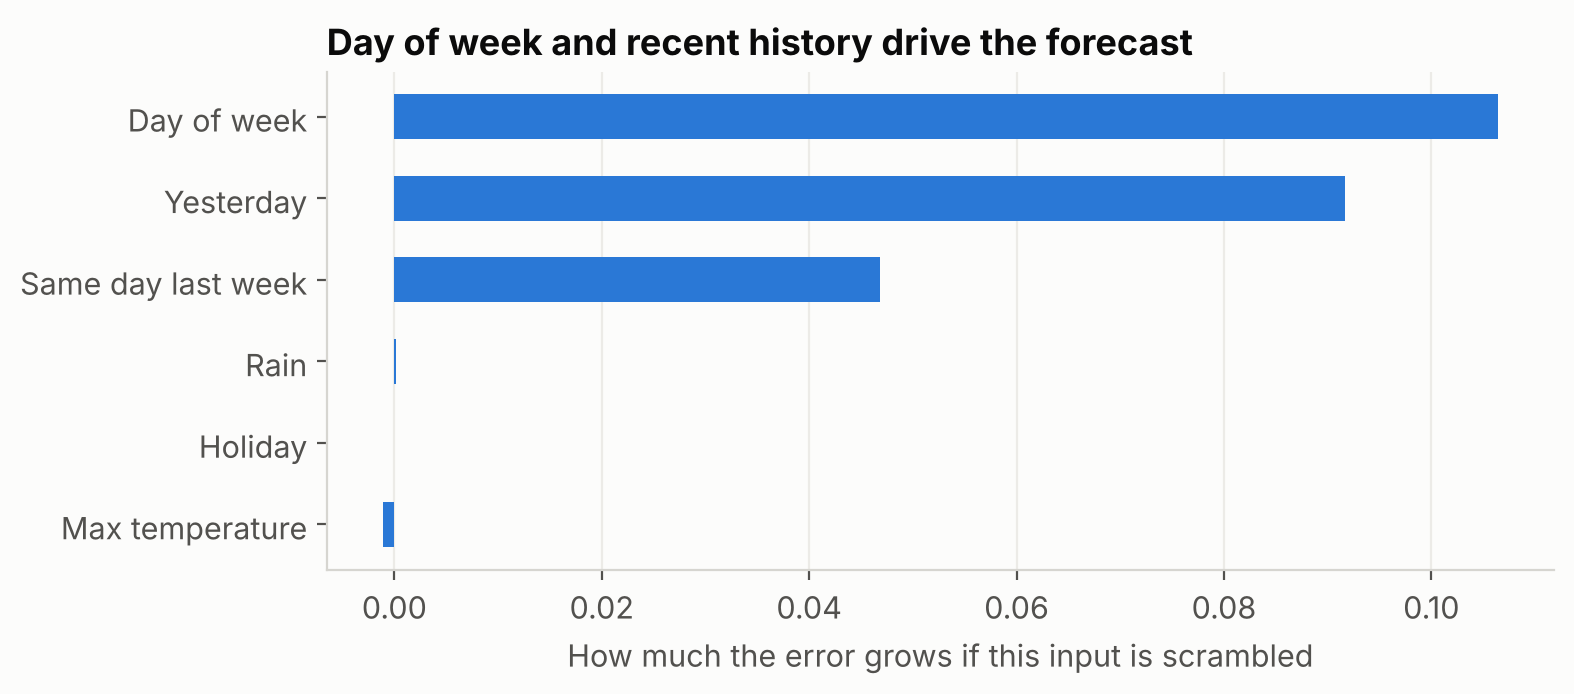

In [11]:
pi = permutation_importance(model, test[FEATS], test.target_r, sample_weight=test.roll7,
                            n_repeats=5, random_state=0, scoring='neg_mean_absolute_error')
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()
labels = {'day_type': 'Day of week', 'holiday': 'Holiday', 'rain_mm': 'Rain', 'tmax_c': 'Max temperature',
          'lag1_r': 'Yesterday', 'lag7_r': 'Same day last week'}
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([labels[i] for i in imp.index], imp.values, color=BLUE, height=0.55)
ax.set_xlabel('How much the error grows if this input is scrambled'); ax.grid(axis='y', visible=False)
ax.set_title('Day of week and recent history drive the forecast')
plt.tight_layout(); plt.savefig('figures/04_feature_importance.png', dpi=150); plt.show()

## 9. Conclusions

**Findings**
1. On unseen September data, our model's error is **7.4%** of riders. That's better than "same day last week" (**9.3%**, about 20% less error) and "August average" (**13.3%**, about 44% less error). The busiest boroughs are the easiest to predict: Manhattan 6.6%, Bronx 9.7%.
2. **Day of week + recent history** (yesterday and the same day last week) do almost all the work. Rain and temperature added **almost nothing**. Two months of mild late-summer weather don't give the model enough variety to learn from.
3. The biggest errors come from **calendar events**: school starting, school holidays and public holidays.

**Recommendation for the MTA**
- Use a model like this to plan **next-day staffing and service at each station**, instead of fixed averages.
- **Add the school calendar and holiday list as inputs.** Those caused the largest misses, and the dates are known months ahead.
- Re-train regularly so the model adjusts to season changes (summer → school year).

**Limitations (be honest)**
- Only **2 months** of data, with no full year of seasons and only one holiday.
- MTA data counts **entries**, not exits, crowding or delays.
- We used *actual* weather for the next day. In real use it would be a *forecast*, which is less accurate.
- Weather comes from **one station** (Central Park) for the whole city.

**Next steps:** a longer history (a full year), school and event calendars, weather forecasts instead of observed weather, and borough-level weather from all three NOAA stations.